# Support vector machine: card fraud detection

Part of the ML Portfolio Model Zoo. Educational purposes only.

Given a card transaction's amount, hour, distance from home, recent activity and channel, estimate the probability that it is fraud with an RBF support vector machine. The data is **synthetic**, generated from a known risk process.

In [1]:
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from train import *

# Everything here reuses train.py, so the notebook and the site always use the same pipeline.

## Data

In [2]:
data = make_data()
print(data.shape)
data.head()

(5000, 6)


,amount,hour_of_day,distance_from_home_km,txns_last_hour,channel,target
0,84.0,13,109.0,0,in-store,0
1,19.0,7,729.0,0,in-store,0
2,137.0,2,10.0,1,in-store,1
3,169.0,10,9.0,2,in-store,0
4,7.0,6,5.0,1,online,0


In [3]:
data.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
amount,5000.0,NaN,NaN,NaN,107.6384,161.316873,1.0,28.0,60.0,120.0,2681.0
hour_of_day,5000.0,NaN,NaN,NaN,11.412,6.925189,0.0,6.0,11.0,17.0,23.0
distance_from_home_km,5000.0,NaN,NaN,NaN,88.7926,312.864814,0.0,8.0,19.0,40.0,2559.0
txns_last_hour,5000.0,NaN,NaN,NaN,0.9978,1.00757,0.0,0.0,1.0,2.0,6.0
channel,5000,3,in-store,2755,NaN,NaN,NaN,NaN,NaN,NaN,NaN
target,5000.0,NaN,NaN,NaN,0.1498,0.356911,0.0,0.0,0.0,0.0,1.0


## Train and evaluate

`train_and_evaluate()` fits the scikit-learn pipeline, scores it on a held-out split, exports it to ONNX and asserts that onnxruntime reproduces scikit-learn's predictions.

In [4]:
result = train_and_evaluate()
print(f"accuracy {result.metrics['accuracy']:.3f}   ROC AUC {result.metrics['roc_auc']:.3f}")
print(f"majority-class baseline {result.metrics['majority_baseline']:.3f} (always guess legitimate)")
print(f"ONNX vs sklearn max abs diff: {result.metrics['onnx_max_abs_diff']:.1e}")

accuracy 0.858   ROC AUC 0.748
majority-class baseline 0.850 (always guess legitimate)
ONNX vs sklearn max abs diff: 1.1e-06


## Charts

The same charts the site shows, written to a temporary folder.

Fraud probability across amount and distance for a 3am online purchase; the line marks 50%.


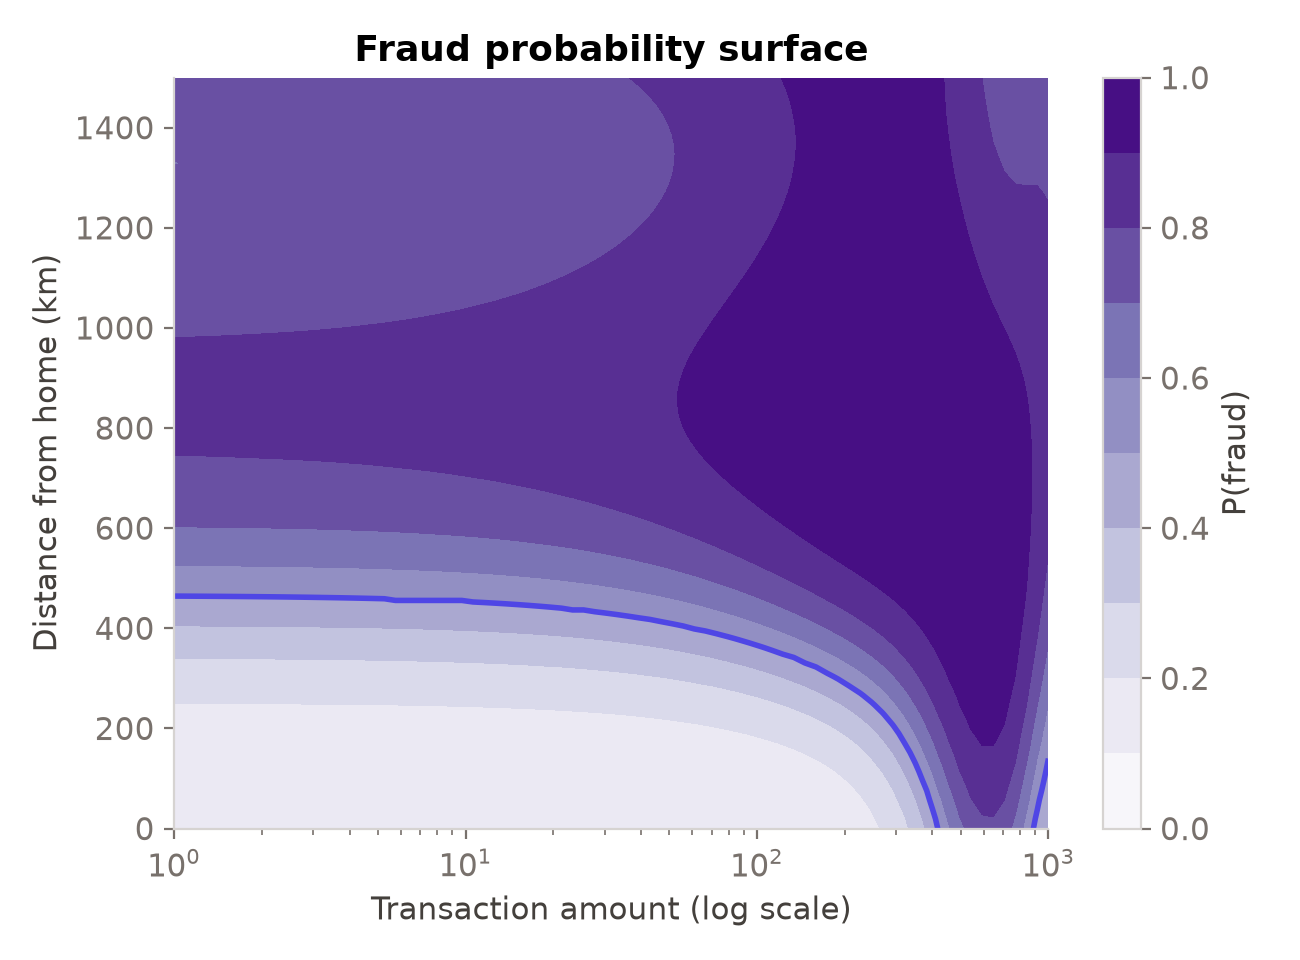

ROC curve on held-out transactions.


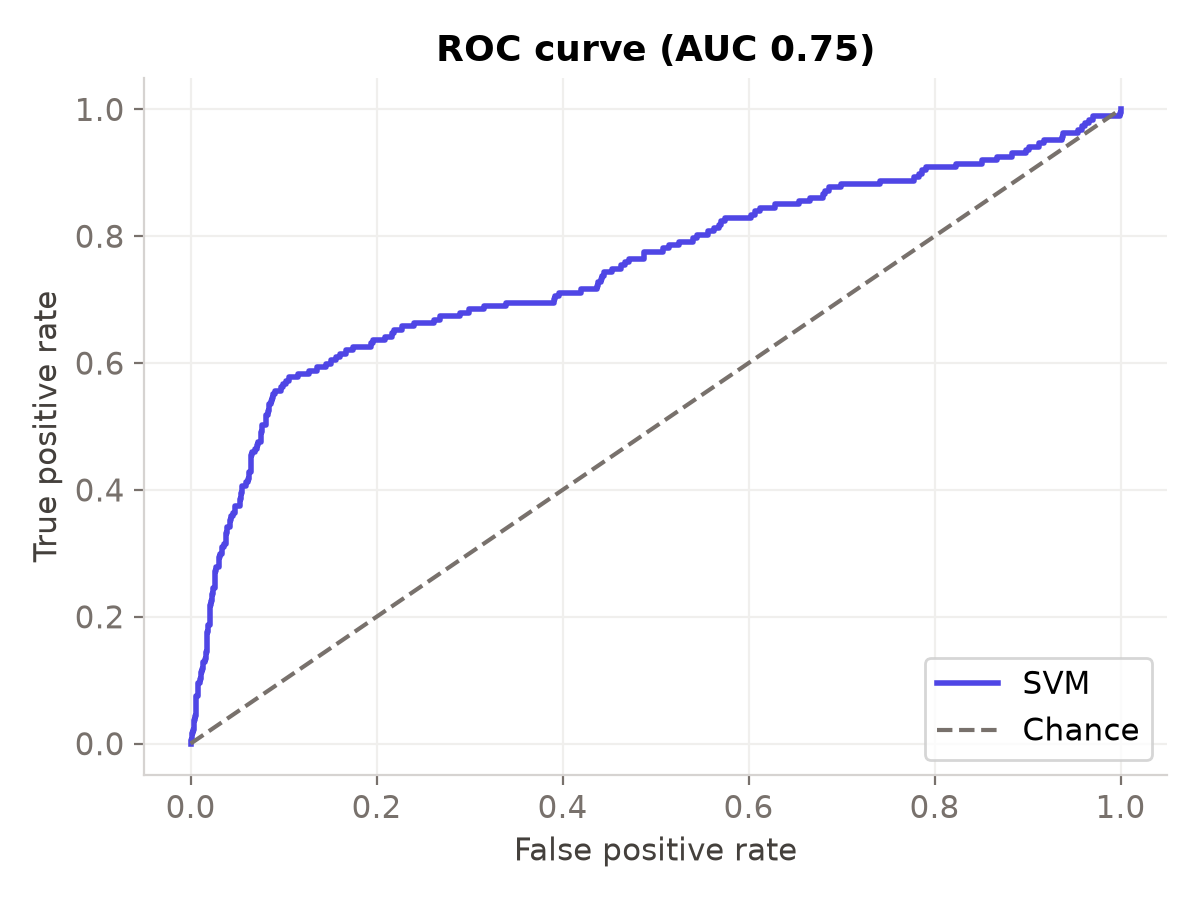

How cleanly predicted fraud probabilities separate the two groups.


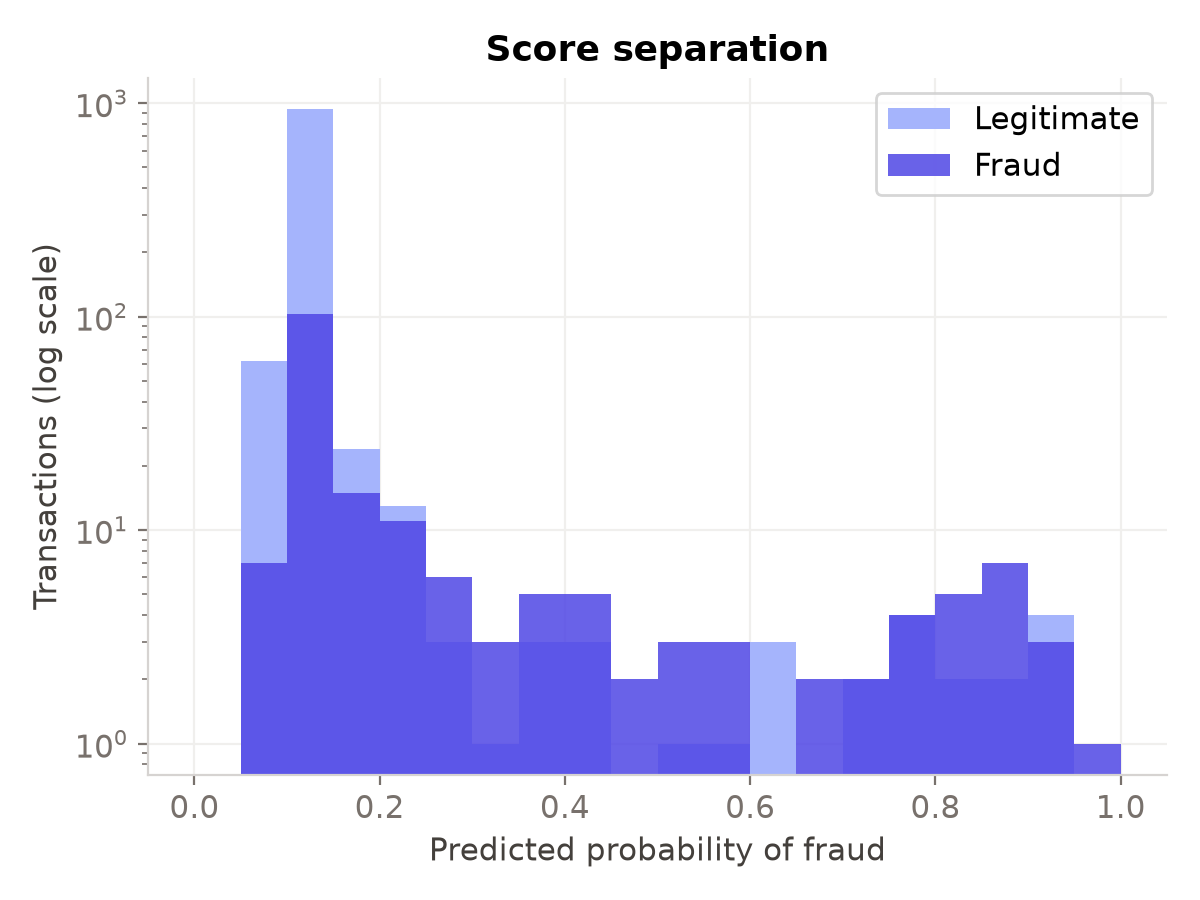

Confusion matrix on held-out data.


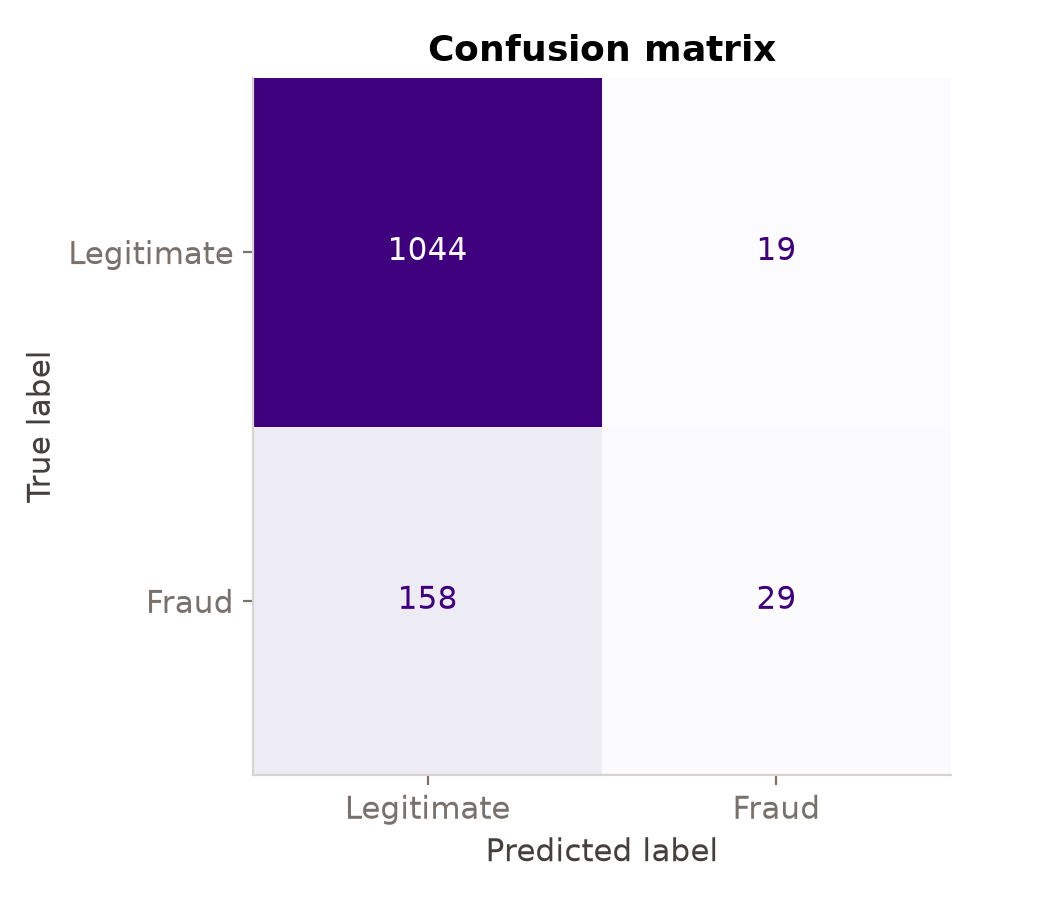

In [5]:
out = Path(tempfile.mkdtemp())
charts = make_charts(result, out)
for c in charts:
    print(c['caption'])
    display(Image(filename=str(out / c['file']), width=620))

## Predict with the exported ONNX model

In [6]:
example = pd.DataFrame([PRESETS[1]["values"]])[ALL_COLUMNS]
_, probs = onnx_predict(result.model_bytes, example)
print("Suspicious burst ->", LABELS[int(probs[0].argmax())], f"(P(fraud) = {probs[0][1]:.1%})")

Suspicious burst -> Fraud (P(fraud) = 55.2%)


## Site artefacts

Run `uv run python train.py` to write `model.onnx`, `schema.json`, the charts and the .NET parity fixtures into the web app. See the README for details.